# 🫁 Synthetic Medical Image Generation for AI Diagnostics
### Generating, Evaluating, and Leveraging Synthetic Chest X-Rays to Improve Diagnostic Models
---
| | |
|---|---|
| **Author** | Ana Farré Matemalas |
| **Institution** | EMLYON Business School |
| **Programme** | MSc Data Science & AI Strategy |
| **Supervisor** | Saeed Varasteh Yazdi |
| **Date** | November 2026 |

---
> *To what extent can synthetic chest X-ray images generated by diffusion models improve the classification performance of AI diagnostic models compared to GAN-based approaches, particularly for minority pathology classes?*

### Notebook 1 — Dataset Understanding and Pneumonia Analysis
---
>Understand the ChestX-ray14 dataset, assess its quality and class distribution, and characterize the Pneumonia and Non-Pneumonia populations used in the subsequent synthetic image generation and classification experiments. Cohort definition, patient-level splits and scenario design are developed in Notebook 2.

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_PATH = '/kaggle/input/datasets/nih-chest-xrays/data'
print(os.listdir(DATA_PATH))

['images_003', 'images_012', 'LOG_CHESTXRAY.pdf', 'README_CHESTXRAY.pdf', 'BBox_List_2017.csv', 'images_009', 'images_008', 'images_007', 'test_list.txt', 'images_010', 'ARXIV_V5_CHESTXRAY.pdf', 'images_002', 'images_011', 'Data_Entry_2017.csv', 'images_001', 'train_val_list.txt', 'images_005', 'FAQ_CHESTXRAY.pdf', 'images_004', 'images_006']


### 1. Initial Setup and Data Loading

This section handles the necessary imports for data manipulation, visualization, and image processing. It also defines the path to the dataset and prints the contents of the data directory to confirm file availability.

In [30]:
import random
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed set to: {SEED}")

Seed set to: 42


### 2. Reproducibility

To ensure that experiments are reproducible, a fixed random seed is set for various libraries like `random`, `numpy`, and `torch`. This ensures that random operations yield the same results across different runs.

In [31]:
df = pd.read_csv(f'{DATA_PATH}/Data_Entry_2017.csv')
print(f"Total images: {len(df)}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst rows:")
df.head()

Total images: 112120

Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']

First rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


### 3. Dataset Overview

Here, the `Data_Entry_2017.csv` file, which contains metadata for the NIH Chest X-ray dataset, is loaded into a Pandas DataFrame. The code then displays the total number of images, lists the available columns, and shows the first few rows of the DataFrame to give an initial understanding of its structure and content.

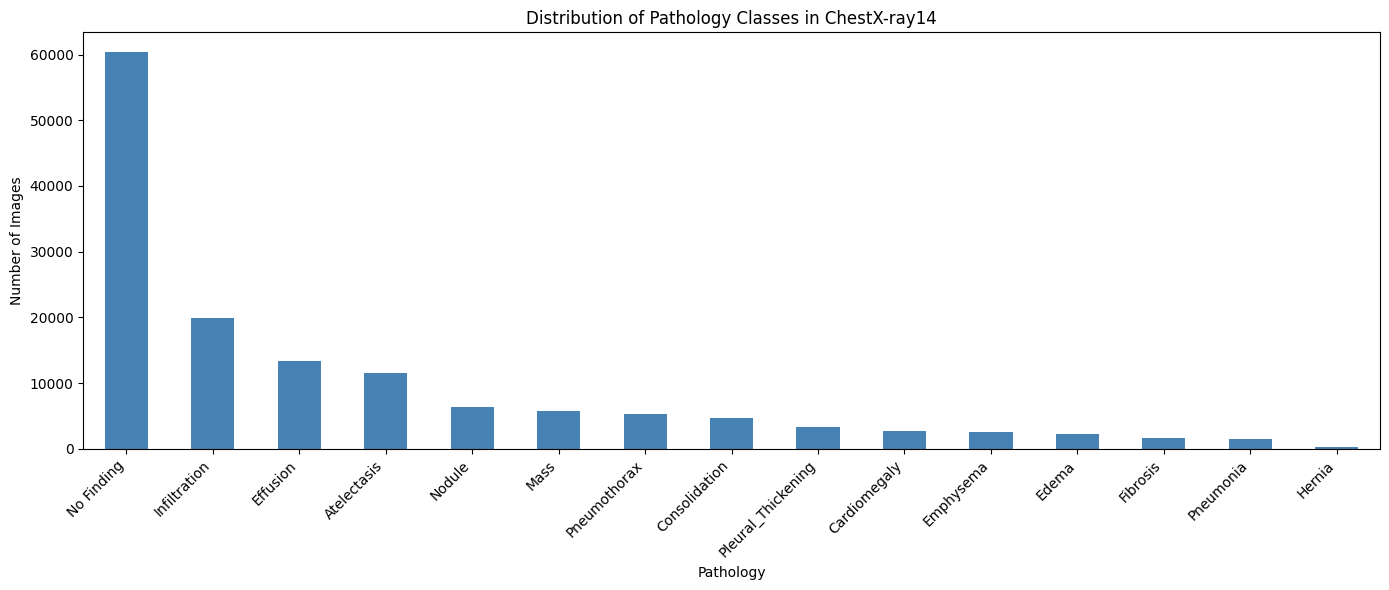

Finding Labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


In [32]:
# Visualize distribution of pathologies
all_labels = df['Finding Labels'].str.split('|').explode()
label_counts = all_labels.value_counts()

plt.figure(figsize=(14, 6))
label_counts.plot(kind='bar', color='steelblue')
plt.title('Distribution of Pathology Classes in ChestX-ray14')
plt.xlabel('Pathology')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(label_counts)

### 4. Pathology Distribution

This section visualizes the distribution of different pathology classes present in the dataset. It extracts all unique 'Finding Labels', counts their occurrences, and plots them as a bar chart. This helps in understanding the frequency of each condition, highlighting potential class imbalances.

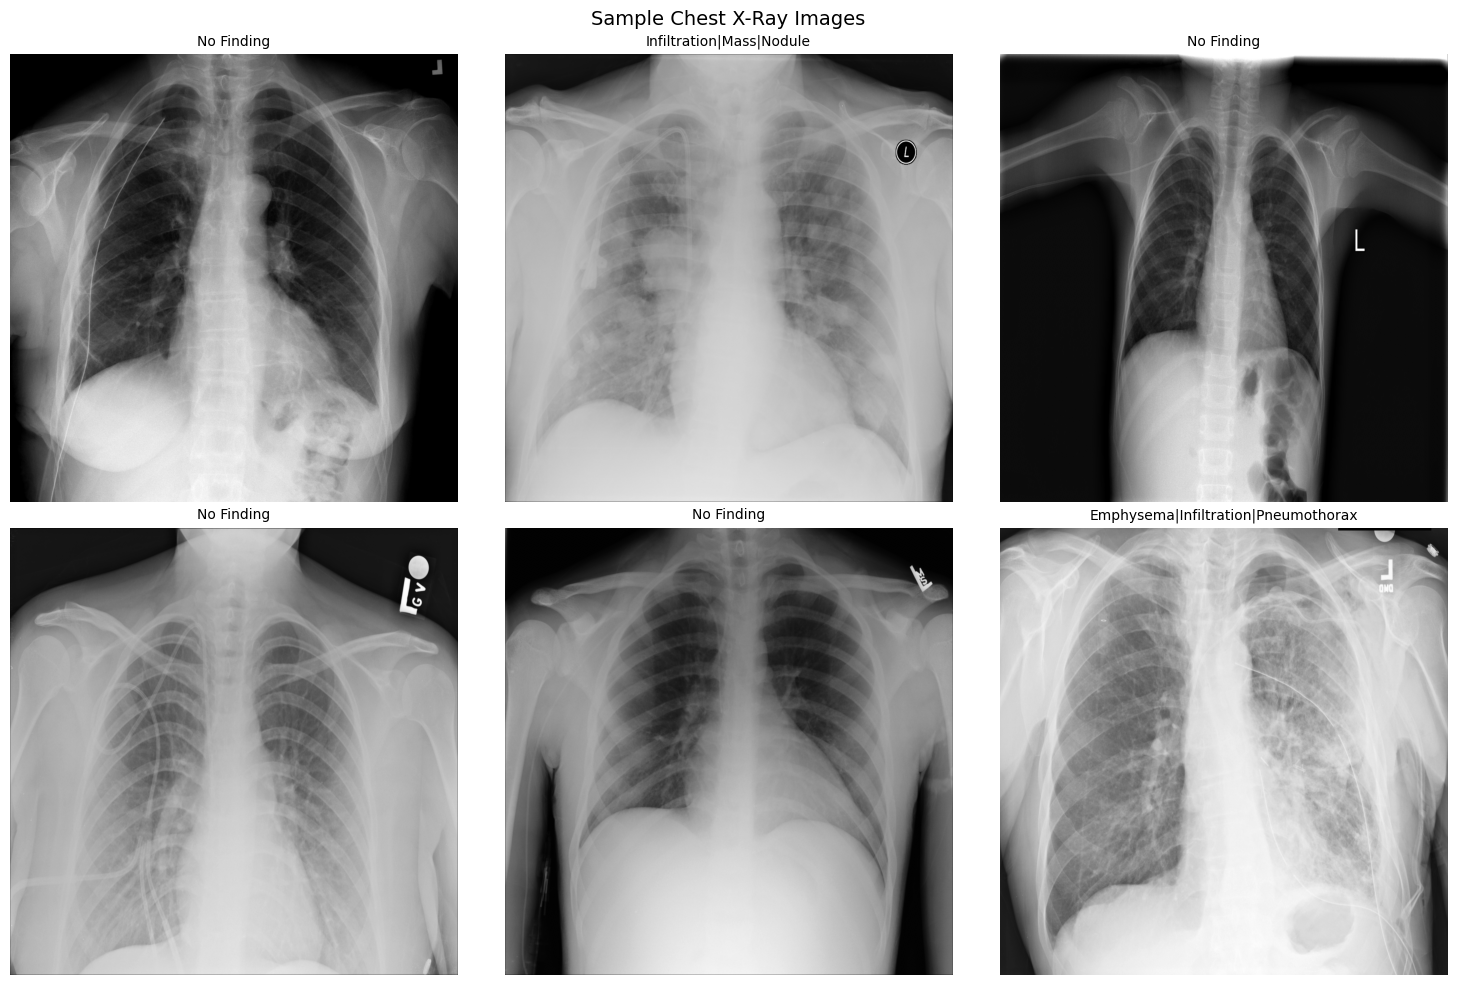

In [33]:
sample = df.sample(6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (_, row) in enumerate(sample.iterrows()):
    img_name = row['Image Index']
    for folder in [f'images_{str(j).zfill(3)}' for j in range(1, 13)]:
        img_path = f'{DATA_PATH}/{folder}/images/{img_name}'
        if os.path.exists(img_path):
            img = Image.open(img_path)
            axes[i].imshow(img, cmap='gray')
            axes[i].set_title(row['Finding Labels'], fontsize=10)
            axes[i].axis('off')
            break

plt.suptitle('Sample Chest X-Ray Images', fontsize=14)
plt.tight_layout()
plt.show()

### 5. Sample Chest X-Ray Images

To visually inspect the data, this code block displays a small sample of chest X-ray images from the dataset. It randomly selects 6 images, locates their corresponding files in the specified data folders, and displays them along with their 'Finding Labels'. This provides a qualitative understanding of the image content and associated annotations.

In [34]:
# --- Full EDA ---

print("Shape:", df.shape)
print("\nInfo:")
print(df.info())
print("\nNull values:")
print(df.isnull().sum())

Shape: (112120, 12)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
 11  Unnamed: 11                  0 non-null       float64
dtypes: float64(3), int64(5), object

### 6. Exploratory Data Analysis (EDA)

This comprehensive EDA section provides insights into the dataset's structure, completeness, and characteristics.

*   **Shape:** Displays the number of rows (images) and columns (features) in the DataFrame.
*   **Info:** Provides a summary of the DataFrame, including column names, non-null counts, and data types, which helps identify missing values and incorrect data types.
*   **Null Values:** Calculates and displays the total number of null values for each column, highlighting columns with missing data that might require handling.

In [35]:
print("Duplicate images (by Image Index):", df['Image Index'].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

Duplicate images (by Image Index): 0
Duplicate rows: 0


### 7. Duplicate Analysis

This section checks for duplicate entries within the dataset, both in terms of 'Image Index' (to identify if the same image appears multiple times) and entire rows. Detecting duplicates is crucial for ensuring data integrity and avoiding biased model training.

In [36]:
df_clean = df.copy()

df_clean = df_clean[df_clean['Patient Age'] <= 120].copy()

df_clean = df_clean.drop(columns=['Unnamed: 11'])

print(f"Original dataset:  {len(df):,} images")
print(f"Cleaned dataset:    {len(df_clean):,} images")
print(f"Removed:        {len(df) - len(df_clean):,} images ({(len(df)-len(df_clean))/len(df)*100:.2f}%)")
print(f"\nPneumonia images: {df_clean['Finding Labels'].str.contains('Pneumonia').sum()}")
print(f"Non-Pneumonia images: {(~df_clean['Finding Labels'].str.contains('Pneumonia')).sum()}")

Original dataset:  112,120 images
Cleaned dataset:    112,104 images
Removed:        16 images (0.01%)

Pneumonia images: 1430
Non-Pneumonia images: 110674


### 8. Data Cleaning

This section performs several data cleaning steps:

1.  **Patient Age Filtering:** Removes entries where 'Patient Age' is greater than 120, as these are likely outliers or erroneous records.
2.  **Dropping 'Unnamed: 11' Column:** The 'Unnamed: 11' column is identified as entirely null during EDA, so it is dropped to clean up the DataFrame.

The code then prints a summary of the original versus cleaned dataset, including the number of removed images and the counts of 'Pneumonia' and 'No Finding' labels in the cleaned dataset.

In [37]:
df = df_clean.copy()
print(df[['Patient Age', 'Patient Gender', 'Follow-up #']].describe())

print("\nGender distribution:")
print(df['Patient Gender'].value_counts())


         Patient Age    Follow-up #
count  112104.000000  112104.000000
mean       46.872574       8.574172
std        16.598152      15.406734
min         1.000000       0.000000
25%        35.000000       0.000000
50%        49.000000       3.000000
75%        59.000000      10.000000
max        95.000000     183.000000

Gender distribution:
Patient Gender
M    63328
F    48776
Name: count, dtype: int64


In [38]:
print("\nPatient information:")
print(f"Unique patients: {df['Patient ID'].nunique():,}")
print(f"Total images: {len(df):,}")

images_per_patient = df.groupby('Patient ID').size()

print("\nImages per patient:")
print(images_per_patient.describe())


Patient information:
Unique patients: 30,802
Total images: 112,104

Images per patient:
count    30802.000000
mean         3.639504
std          7.266232
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
dtype: float64


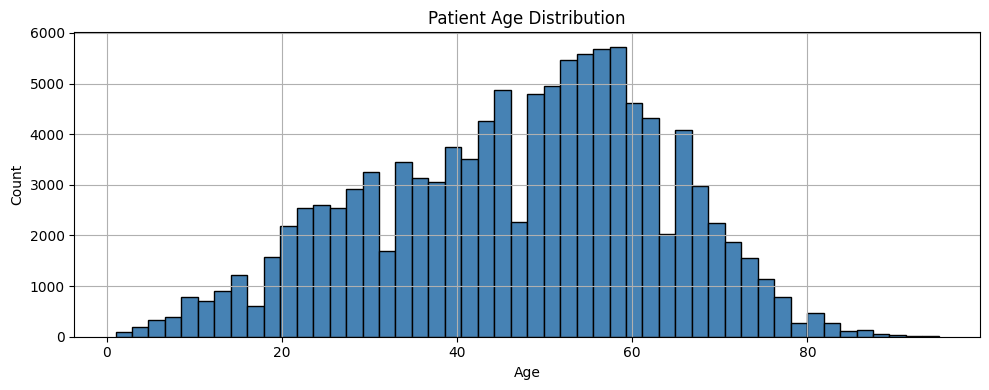

In [39]:
plt.figure(figsize=(10, 4))
df['Patient Age'].hist(bins=50, color='steelblue', edgecolor='black')
plt.title('Patient Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [40]:
df['Pneumonia'] = df['Finding Labels'].str.contains('Pneumonia').astype(int)
pneumonia_df = df[df['Pneumonia'] == 1]
non_pneumonia_df = df[df['Pneumonia'] == 0]

### 9. Patient Demographics Analysis

This part of the EDA focuses on patient demographic information:

*   **Descriptive Statistics:** Provides a statistical summary of 'Patient Age', 'Patient Gender', and 'Follow-up #' columns.
*   **Gender Distribution:** Shows the counts of male and female patients.
*   **Patient Age Distribution:** Visualizes the age distribution of patients using a histogram, offering insights into the age groups most represented in the dataset.

In [41]:
# 4. Images with multiple labels (multi-label)

# Number of labels per image
df['num_labels'] = df['Finding Labels'].apply(
    lambda x: len(x.split('|'))
)

print("Distribution of number of labels per image:")
print(df['num_labels'].value_counts().sort_index())

# Define Pneumonia and Non-Pneumonia groups
pneumonia_df = df[df['Pneumonia'] == 1]
non_pneumonia_df = df[df['Pneumonia'] == 0]

print("\nPneumonia images by number of labels:")
print(pneumonia_df['num_labels'].value_counts().sort_index())

print(f"\nTotal images with Pneumonia: {len(pneumonia_df):,}")
print(f"Total images without Pneumonia: {len(non_pneumonia_df):,}")

print("\nLabels accompanying Pneumonia:")
print(pneumonia_df['Finding Labels'].value_counts().head(10))

Distribution of number of labels per image:
num_labels
1    91312
2    14302
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64

Pneumonia images by number of labels:
num_labels
1    322
2    543
3    386
4    138
5     34
6      3
7      3
9      1
Name: count, dtype: int64

Total images with Pneumonia: 1,430
Total images without Pneumonia: 110,674

Labels accompanying Pneumonia:
Finding Labels
Pneumonia                             322
Infiltration|Pneumonia                199
Edema|Infiltration|Pneumonia          137
Atelectasis|Pneumonia                 108
Edema|Pneumonia                        83
Effusion|Pneumonia                     53
Effusion|Infiltration|Pneumonia        42
Consolidation|Pneumonia                36
Atelectasis|Infiltration|Pneumonia     34
Atelectasis|Effusion|Pneumonia         23
Name: count, dtype: int64


### 10. Multi-label Analysis and Pneumonia Cases

This section explores images with multiple 'Finding Labels' and specifically examines cases involving 'Pneumonia':

1.  **Number of Labels Distribution:** A new column `num_labels` is created to count how many pathologies are associated with each image, and its distribution is printed.
2.  **Pneumonia Co-occurrences:** It identifies all images that include 'Pneumonia' as a finding and then lists the most frequent 'Finding Labels' that appear alongside 'Pneumonia'. This helps understand common comorbidities.

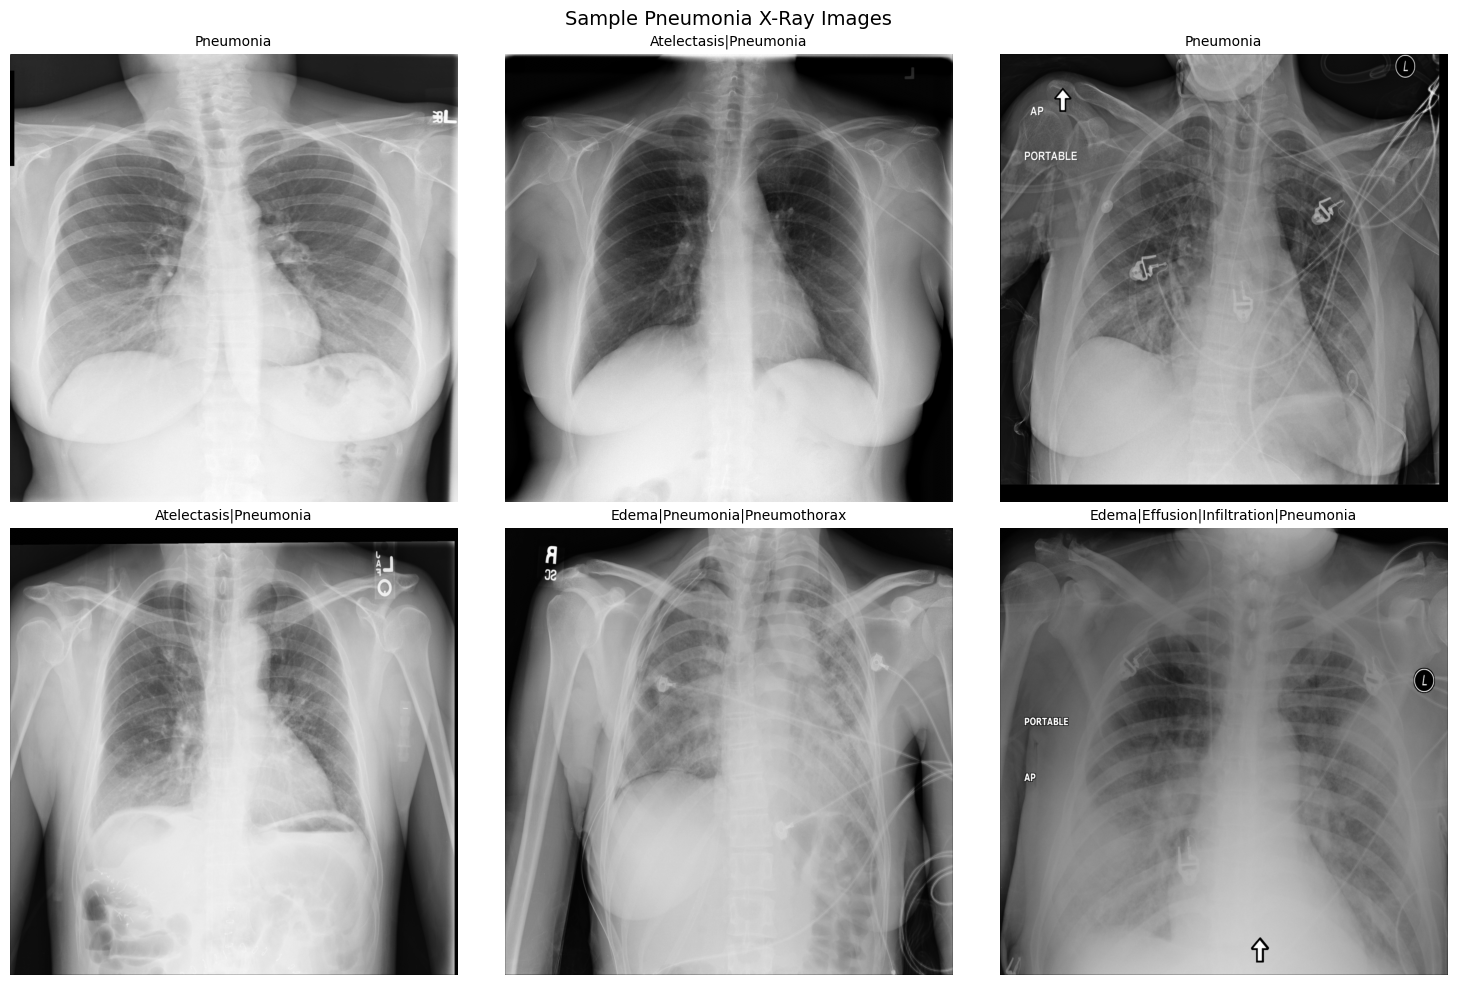

In [42]:
pneumonia_sample = pneumonia_df.sample(6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (_, row) in enumerate(pneumonia_sample.iterrows()):
    img_name = row['Image Index']
    for folder in [f'images_{str(j).zfill(3)}' for j in range(1, 13)]:
        img_path = f'{DATA_PATH}/{folder}/images/{img_name}'
        if os.path.exists(img_path):
            img = Image.open(img_path)
            axes[i].imshow(img, cmap='gray')
            axes[i].set_title(row['Finding Labels'], fontsize=10)
            axes[i].axis('off')
            break

plt.suptitle('Sample Pneumonia X-Ray Images', fontsize=14)
plt.tight_layout()
plt.show()

### 11. Sample Pneumonia X-Ray Images

Similar to the general image sampling, this block specifically displays a selection of chest X-ray images that are labeled with 'Pneumonia'. This visual inspection helps to understand the appearance of pneumonia cases and how they might be represented in the dataset, particularly when co-occurring with other conditions.

### 12. Age and Gender Distribution of Pneumonia Cases

This visualization specifically examines the demographic characteristics of patients diagnosed with pneumonia. Understanding the age and gender distribution within the pneumonia cohort can provide valuable insights for tailoring synthetic data generation to match real-world patient demographics, particularly for this minority class.

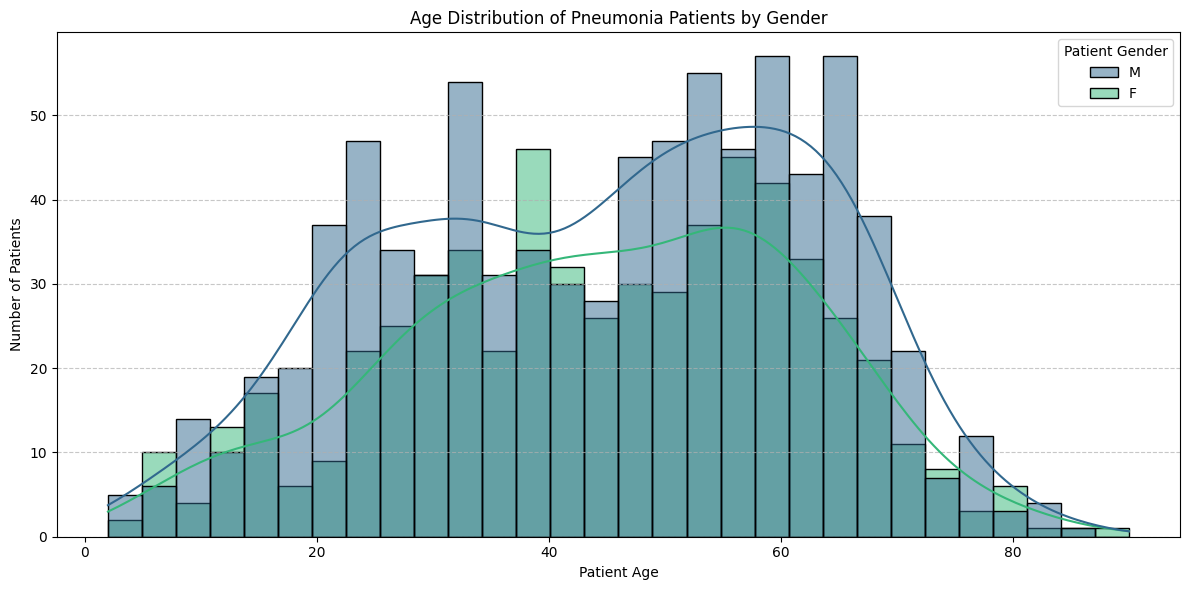

/tmp/ipykernel_529/2611794096.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pneumonia_df, x='Patient Gender', palette='viridis')


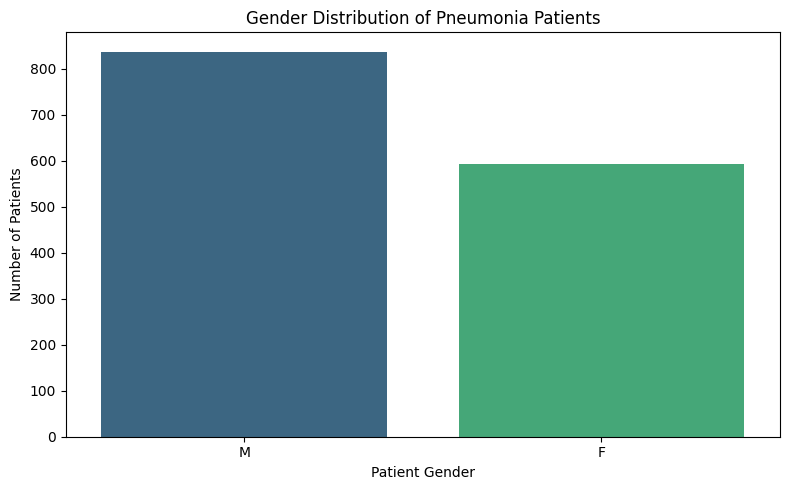

In [43]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.histplot(data=pneumonia_df, x='Patient Age', hue='Patient Gender', bins=30, kde=True, palette='viridis')
plt.title('Age Distribution of Pneumonia Patients by Gender')
plt.xlabel('Patient Age')
plt.ylabel('Number of Patients')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=pneumonia_df, x='Patient Gender', palette='viridis')
plt.title('Gender Distribution of Pneumonia Patients')
plt.xlabel('Patient Gender')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

### 13. Ratio of Pneumonia Cases to Non-Pneumonia Cases

Quantifying the imbalance between pneumonia and non-pneumonia cases is crucial for understanding the severity of the class imbalance. This calculation provides a direct measure of how underrepresented the pneumonia class is within the dataset, further motivating the need for synthetic data generation.

In [44]:
class_counts = df['Pneumonia'].value_counts()

num_pneumonia_cases = class_counts[1]
num_non_pneumonia_cases = class_counts[0]

print(f"Pneumonia cases: {num_pneumonia_cases:,}")
print(f"Non-Pneumonia cases: {num_non_pneumonia_cases:,}")

print(
    f"\nPneumonia percentage: "
    f"{num_pneumonia_cases / len(df) * 100:.2f}%"
)

print(
    f"Non-Pneumonia percentage: "
    f"{num_non_pneumonia_cases / len(df) * 100:.2f}%"
)

Pneumonia cases: 1,430
Non-Pneumonia cases: 110,674

Pneumonia percentage: 1.28%
Non-Pneumonia percentage: 98.72%


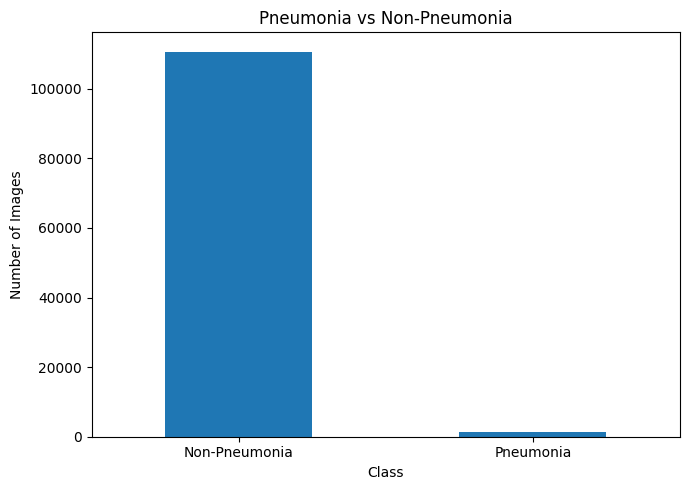

In [45]:
plt.figure(figsize=(7, 5))

df['Pneumonia'].value_counts().sort_index().plot(
    kind='bar'
)

plt.xticks(
    [0, 1],
    ['Non-Pneumonia', 'Pneumonia'],
    rotation=0
)

plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.title('Pneumonia vs Non-Pneumonia')
plt.tight_layout()
plt.show()

### Impact of Label Imbalance on Synthetic Image Models

Label imbalance, where certain classes (like 'Pneumonia' in your dataset) are significantly underrepresented compared to others ('No Finding'), poses a substantial challenge for training synthetic image generation models (e.g., GANs, VAEs, Diffusion Models). Here's how it impacts them:

1.  **Bias Towards Majority Classes:** Generative models learn the underlying data distribution. If a class is rare, the model will see very few examples of it during training. Consequently, it will primarily learn the features of the majority classes and may struggle to accurately capture the subtle or defining characteristics of the minority class (e.g., the specific patterns of pneumonia in X-rays).

2.  **Poor Quality or Non-Representative Samples:** When asked to generate samples from a minority class, the model might produce low-quality, ambiguous, or even misclassified images. It might 'hallucinate' features that are common in majority classes rather than generating true-to-life minority class examples.

3.  **Mode Collapse:** Especially in GANs, mode collapse can occur where the generator produces only a limited variety of samples, often favoring the more common features or classes. This is exacerbated with imbalanced data, as the generator might simply learn to produce variations of the majority class, even when explicitly conditioned on a minority class.

4.  **Difficulty in Learning Complex Relationships:** Minority classes often represent more complex or nuanced conditions. With limited data, the model struggles to learn the intricate relationships between features that define these conditions, leading to less effective synthetic data.

5.  **Impact on Downstream Task (Classifier Training):** The ultimate goal of synthetic data in this context is often to augment a dataset to improve a diagnostic classifier. If the synthetic images generated for the minority class are biased or of poor quality, they might not effectively help the classifier learn to differentiate the minority class from others, or worse, they could introduce noise and degrade classifier performance.

### Strategies to Mitigate:

To address this, techniques like oversampling the minority class during generative model training, using weighted loss functions, or employing more advanced conditional generation methods (where the model is explicitly guided to generate specific classes) are often necessary. The choice of generative model itself can also play a role, with some (like diffusion models) potentially being more robust to imbalance than others.